# 04 · Vecchia prototype: evaluation against core + halo

This notebook compares the two Vecchia variants of `03_vecchia_prototype.ipynb` with the core + halo operator now in rcorr, the symmetrised Ãₛ. It covers everything that matters operationally:

1. **Accuracy:** generalised eigenvalues of C̃⁻¹C, KL divergence, the error of Jₒ and of R⁻¹d for real departures.
2. **Symmetry and positive definiteness.**
3. **Implied covariance:** the variances and correlations that perturbations would have.
4. **Setup cost:** flops, the communication pattern, rounds.
5. **Apply cost:** flops, bytes, peers.
6. **Sampling:** rounds of the forward substitution.
7. **Behaviour from 96 to 1024 tasks.**

The notebook only reads results: the JSON files in `experiments/vecchia_results/` (set `VECCHIA_RESULTS` to read another
directory). They come from three scripts:

| results | script | where it runs |
|---|---|---|
| `golden.json` | `experiments/vecchia_golden.py` | login node, about 5 min |
| `acc_ch*_s*_a*_P*.json` | `experiments/vecchia_seviri.py <npz> <channel> <slot> <alpha> <P> <out>` | Slurm array, one image per task |
| `scaling.json` | `experiments/vecchia_scaling.py <npz> <out>` | Slurm, about 15 min |

The real data are all active Met-11 SEVIRI clear-sky radiances of the jdj6 cycle 2022-06-01 00 UTC, 203 633 data:
* ch5: 128k
* ch6: 64k
* ch9: 12k

The input file (`jdj6_20220601_00.npz`, extracted from the experiment's observation feedback) is ECMWF data and is not in
the repository, so the real-data results can be read here but not regenerated without it. Each group is one channel × one 15-min slot (36 groups). d = fg_depar / σ_o, c = ℓ = 115 km, and the GC support is 2ℓ = 230 km. The **patches are the RCB partition of all data of the cycle** into P patches, as rcorr does, so a single image has few data per patch at large P.

In [1]:
import glob, json, os, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
RES = Path(os.environ.get("VECCHIA_RESULTS", Path.cwd().parent / "experiments" / "vecchia_results")).expanduser()
COL = {"core+halo": "#2a78d6", "block": "#eb6834", "point": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "grid.linewidth": 0.6})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print(RES.name)

vecchia_results


## 1. Golden cases

There are 9 cases: uniform, clustered, several groups, poles and dateline, the geostationary disc, two classes, inactive data, and a short halo. Data and parameters are those of `export.CASES`, with c of 400 to 1500 km, α of 0.8 to 0.9 and h of 1.5c to 4c. We use 8 RCB patches. Every operator uses the class's halo width h.
* **core + halo:** symmetrised.
* **block:** one-sided halo of the same width.
* **point:** m nearest earlier data.

In [2]:
g = json.load(open(RES / "golden.json"))
d2 = pd.DataFrame([x for x in g if x["method"] == "d2"]).set_index("case")[["point", "block"]]
gd = pd.DataFrame([x for x in g if x["method"] != "d2"])
gd["variant"] = (gd.method + " " + gd.seq.fillna("") + gd.order.fillna("") + " " + gd.m.fillna(0).astype(int).astype(str)).str.replace(" 0$", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
keep = ["core+halo", "block colour", "block id", "point maxmin 10", "point maxmin 20", "point maxmin 50", "point patch 20"]
t = gd[gd.P == 8].pivot_table(index=["case", "group", "n", "alpha", "h_over_c"], columns="variant", values="max_dev", aggfunc="first")[keep]
print("max |lambda - 1| (8 patches)")
display(t.style.format("{:.1e}"))
print("smallest eigenvalue over all cases and groups (> 0: SPD):")
display(gd.groupby("variant")["lam_min"].min().to_frame().T.style.format("{:.3f}"))
print("D2: C~^-1 x bit-identical on 1, 2, 4, 7 tasks (8 fixed patches)")
display(d2.T)

max |lambda - 1| (8 patches)


smallest eigenvalue over all cases and groups (> 0: SPD):


variant,block colour,block id,core+halo,point maxmin 10,point maxmin 20,point maxmin 5,point maxmin 50,point patch 10,point patch 20,point patch 5,point patch 50
lam_min,0.901,0.929,0.934,0.437,0.502,0.295,0.668,0.357,0.473,0.230,0.647


D2: C~^-1 x bit-identical on 1, 2, 4, 7 tasks (8 fixed patches)


case,tiny,sph_uniform,sph_clustered,sph_groups,sph_poles_dateline,sph_geo_disc,sph_classes,sph_inactive,sph_short_halo
point,True,True,True,True,True,True,True,True,True
block,True,True,True,True,True,True,True,True,True


In [3]:
h = gd[gd.P == 8].pivot_table(index=["case", "group"], columns="variant", values="halo_over_core", aggfunc="first")[["core+halo", "block colour", "point maxmin 20", "point maxmin 50"]]
r = gd[gd.P == 8].pivot_table(index=["case", "group"], columns="variant", values="sample_rounds", aggfunc="first")[["block colour", "block id", "point maxmin 20", "point patch 20"]]
display(pd.concat({"halo / core": h, "sampling rounds": r}, axis=1).style.format("{:.2f}", subset=pd.IndexSlice[:, "halo / core"]).format("{:.0f}", subset=pd.IndexSlice[:, "sampling rounds"]))

**Golden cases, in short.**

* **Block Vecchia** is as accurate as the symmetrised core + halo at the same h on every case, often better. Examples: geo disc 3e-2 against 7e-2, clustered 3e-3 against 1e-2. It needs half the halo.
* **Point Vecchia** depends on how many data lie within the correlation length. Where the data are dense relative to c (clustered with α 0.9, geo disc), m ≤ 20 gives max |λ − 1| of about 1, i.e. λ_min of about 0.5. It is still SPD.
* **SPD and D2:** every variant is SPD everywhere, and all are bit-identical across task counts.

## 2. One real image: accuracy, implied covariance, costs

Each `acc_*.json` holds one image, one α and one P, with these operators:
* **core + halo:** h = 2, 3, 4c.
* **block:** sequence `colour`, h = 2, 3, 4, 6c; sequence `id`, h = 4c.
* **point:** orderings `maxmin` and `patch`, m = 30, 50, 100.

**Columns:**

| column | meaning |
|---|---|
| `max_dev`, `lam_min`, `kl` | generalised eigenvalues of C̃⁻¹C |
| `jo_rel` | relative error of dᵀC̃⁻¹d for the real d |
| `z_rel` | relative error of C̃⁻¹d |
| `var_err_max` | largest error of the implied variances diag(C̃) (what EDA perturbations would have) |
| `cov_err_max` | largest error of any implied covariance |
| `flops_apply_max/total` | one C̃⁻¹x: on the busiest patch, and summed. For core + halo this is two right-hand sides through the Cholesky factor, as rcorr does today |
| `flops_apply_explicit_max` | core + halo with the core rows of R_loc⁻¹ stored explicitly: a cheaper apply that rcorr could adopt (not in all files) |
| `flops_setup_max` | the factorisation on the busiest patch |
| `bytes_apply`, `peers_max` | communication of one C̃⁻¹x |
| `bytes_setup`, `collectives_setup`, `rounds_setup` | communication of the setup |
| `sample_rounds` | sequential communication rounds of x = W⁻¹z |

In [4]:
rows = []
for f in sorted(glob.glob(str(RES / "acc_ch*_s*_a*_P*.json"))):
    r = json.load(open(f))
    for x in r["rows"]:
        rows.append(dict(channel=r["channel"], slot=r["slot"], alpha=r["alpha"], P=r["P"], n=r["n"], **x))
acc = pd.DataFrame(rows)
acc["param"] = acc.h_over_c.where(acc.method != "point", acc.m)
acc["variant"] = acc.method + np.where(acc.method == "block", " " + acc.seq.fillna(""), "") + np.where(acc.method == "point", " " + acc.order.fillna(""), "")
acc["label"] = acc.variant + np.where(acc.method == "point", " m=" + acc.m.fillna(0).astype(int).astype(str), " h=" + acc.h_over_c.astype(str) + "c")
cases = acc.groupby(["channel", "slot", "alpha", "P", "n"]).size().rename("operators").reset_index()
cases

,channel,slot,alpha,P,n,operators
0,5,28,0.5,96,11415,14
1,5,28,0.7,96,11415,14
2,5,28,0.7,1024,11415,14
3,6,8,0.7,96,5871,14
4,6,28,0.5,96,5728,14
5,6,28,0.5,1024,5728,14
6,6,28,0.7,96,5728,14
7,6,28,0.7,384,5728,14
8,6,28,0.7,1024,5728,14
9,6,28,0.9,96,5728,14


In [5]:
for c_ in ("flops_apply_explicit_max", "flops_setup_explicit_max"):
    if c_ not in acc:
        acc[c_] = np.nan
cols = ["label", "max_dev", "lam_min", "kl", "jo_rel", "z_rel", "var_err_max", "cov_err_max", "halo_over_core", "peers_max",
        "flops_apply_max", "flops_apply_explicit_max", "flops_apply_total", "flops_setup_max", "bytes_apply", "bytes_setup", "rounds_setup", "sample_rounds"]
fmt = {c: "{:.1e}" for c in ["max_dev", "kl", "jo_rel", "z_rel", "var_err_max", "cov_err_max", "flops_apply_max", "flops_apply_explicit_max", "flops_apply_total", "flops_setup_max", "bytes_apply", "bytes_setup"]}
fmt.update(lam_min="{:.4f}", halo_over_core="{:.2f}", peers_max="{:.0f}", rounds_setup="{:.0f}", sample_rounds="{:.0f}")
def show(channel, slot, alpha, P):
    s = acc[(acc.channel == channel) & (acc.slot == slot) & (acc.alpha == alpha) & (acc.P == P)][cols]
    print(f"ch{channel} slot {slot}, alpha {alpha}, P = {P}, n = {acc[(acc.channel == channel) & (acc.slot == slot)].n.iloc[0]}")
    display(s.set_index("label").style.format(fmt, na_rep="-"))
show(6, 28, 0.5, 96)

ch6 slot 28, alpha 0.5, P = 96, n = 5728


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,1.1e-02,0.9892,4.0e-03,1.3e-04,2.2e-03,7.7e-05,6.7e-03,0.90,8,2.2e+05,-,6.0e+06,4.3e+06,8.3e+04,1.1e+06,-,-
core+halo h=3.0c,2.6e-03,0.9974,4.1e-05,-5.5e-06,2.2e-04,4.2e-06,1.6e-03,1.53,10,3.8e+05,-,1.1e+07,9.8e+06,1.4e+05,1.4e+06,-,-
core+halo h=4.0c,2.5e-04,0.9998,3.5e-07,-1.4e-07,2.0e-05,3.9e-08,1.5e-04,2.23,10,6.6e+05,-,1.7e+07,2.2e+07,2.0e+05,1.7e+06,-,-
block colour h=2.0c,2.0e-02,0.9798,6.5e-03,8.5e-05,2.6e-03,6.6e-05,9.9e-03,0.44,7,6.6e+04,-,1.2e+06,7.3e+06,4.1e+04,3.7e+05,1,4
block colour h=3.0c,3.5e-03,0.9965,7.2e-05,-4.0e-06,3.2e-04,3.9e-07,2.6e-03,0.77,9,1.0e+05,-,1.6e+06,1.7e+07,7.1e+04,4.9e+05,1,4
block colour h=4.0c,2.2e-04,0.9998,4.9e-07,-3.2e-07,2.3e-05,1.0e-08,1.4e-04,1.11,9,1.2e+05,-,2.1e+06,3.2e+07,1.0e+05,6.0e+05,1,5
block colour h=6.0c,3.9e-06,1.0000,2.8e-11,4.2e-10,1.6e-07,9.0e-13,2.4e-06,1.95,12,2.2e+05,-,3.0e+06,1.2e+08,1.8e+05,8.4e+05,1,6
block id h=4.0c,2.1e-04,0.9998,5.0e-07,-2.4e-07,2.2e-05,6.8e-09,1.4e-04,1.10,6,8.4e+04,-,2.1e+06,1.2e+07,1.0e+05,6.2e+05,1,24
point maxmin m=30,1.9e-02,0.9811,6.8e-03,3.0e-05,2.6e-03,1.2e-04,8.4e-03,2.94,55,2.2e+04,-,7.1e+05,1.9e+06,2.7e+05,3.7e+07,6,279


In [6]:
show(6, 28, 0.7, 96)

ch6 slot 28, alpha 0.7, P = 96, n = 5728


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,3.2e-02,0.9691,3.0e-02,5.6e-05,5.9e-03,6.7e-04,2.0e-02,0.90,8,2.2e+05,-,6.0e+06,4.3e+06,8.3e+04,1.1e+06,-,-
core+halo h=3.0c,7.8e-03,0.9923,6.4e-04,1.3e-06,8.2e-04,4.0e-05,5.3e-03,1.53,10,3.8e+05,-,1.1e+07,9.8e+06,1.4e+05,1.4e+06,-,-
core+halo h=4.0c,1.1e-03,0.9989,1.3e-05,-2.7e-06,1.2e-04,8.3e-07,7.2e-04,2.23,10,6.6e+05,-,1.7e+07,2.2e+07,2.0e+05,1.7e+06,-,-
block colour h=2.0c,5.5e-02,0.9451,4.7e-02,2.9e-05,6.8e-03,3.7e-04,2.8e-02,0.44,7,6.6e+04,-,1.2e+06,7.3e+06,4.1e+04,3.7e+05,1,4
block colour h=3.0c,1.1e-02,0.9891,9.9e-04,-4.9e-06,1.1e-03,8.7e-06,8.1e-03,0.77,9,1.0e+05,-,1.6e+06,1.7e+07,7.1e+04,4.9e+05,1,4
block colour h=4.0c,1.5e-03,0.9985,1.7e-05,-3.3e-06,1.3e-04,2.5e-07,9.1e-04,1.11,9,1.2e+05,-,2.1e+06,3.2e+07,1.0e+05,6.0e+05,1,5
block colour h=6.0c,4.7e-05,1.0000,5.4e-09,5.0e-08,2.3e-06,2.6e-10,1.7e-05,1.95,12,2.2e+05,-,3.0e+06,1.2e+08,1.8e+05,8.4e+05,1,6
block id h=4.0c,1.5e-03,0.9985,2.0e-05,-2.3e-06,1.4e-04,1.8e-07,9.4e-04,1.10,6,8.4e+04,-,2.1e+06,1.2e+07,1.0e+05,6.2e+05,1,24
point maxmin m=30,4.6e-02,0.9554,5.7e-02,1.8e-05,7.8e-03,9.9e-04,1.9e-02,2.94,55,2.2e+04,-,7.1e+05,1.9e+06,2.7e+05,3.7e+07,6,279


### 2.1 Accuracy against communication and against apply cost

Every operator is one point, and a line joins one family as its parameter grows: h for core + halo and block, m for point.
* **Left:** accuracy against the bytes of one application.
* **Middle:** accuracy against the flops of the busiest patch.
* **Right:** accuracy against the setup flops of the busiest patch.

Lower left is better.

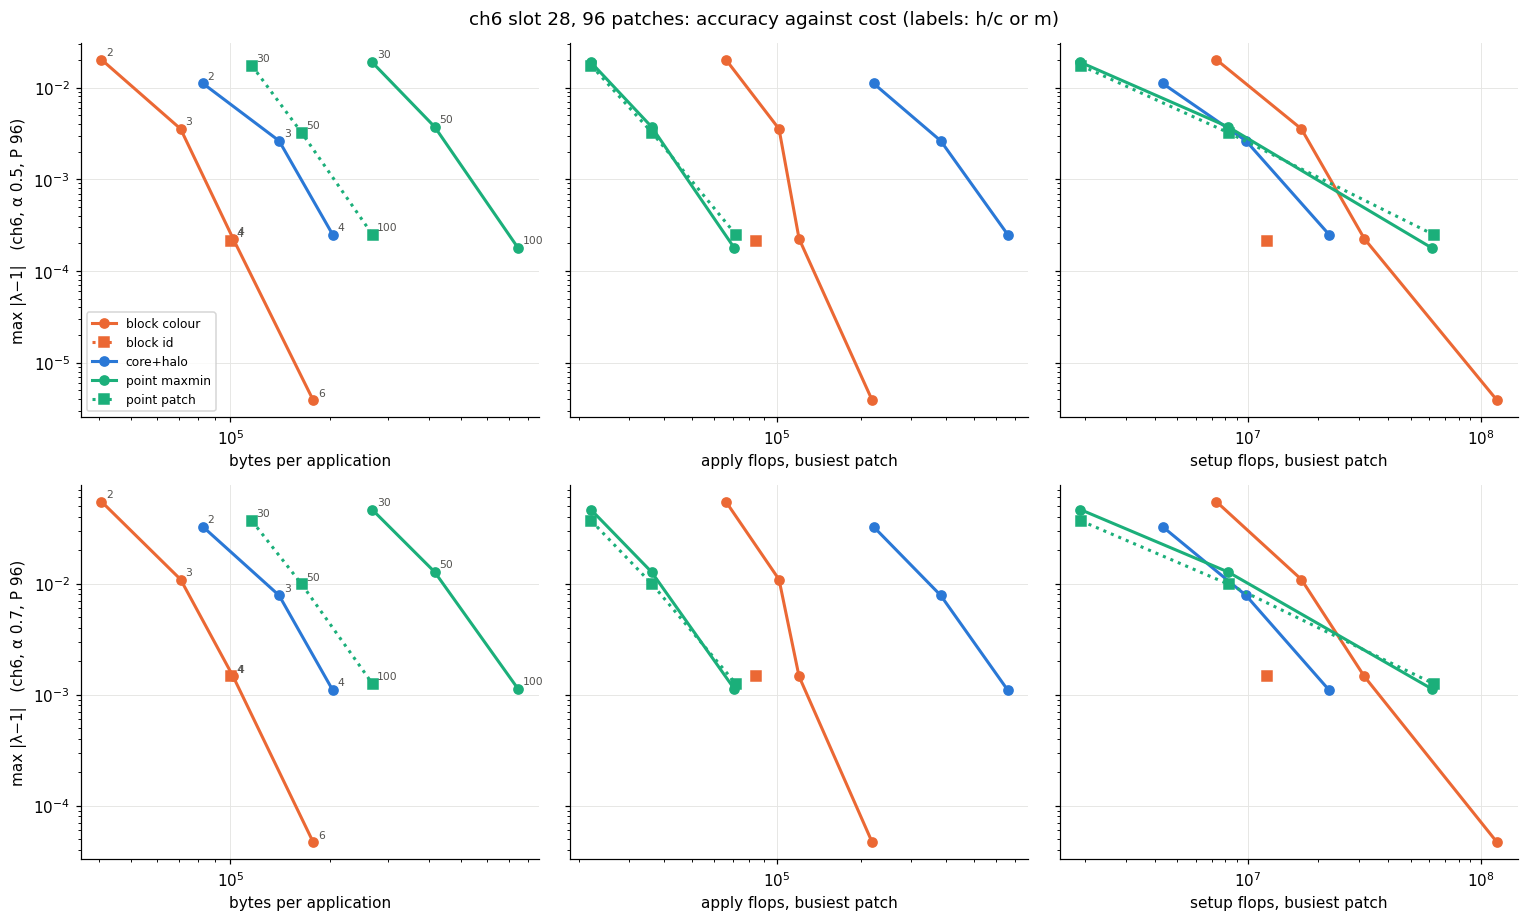

In [7]:
def pareto(channel, slot, alpha, P, ax_row):
    s = acc[(acc.channel == channel) & (acc.slot == slot) & (acc.alpha == alpha) & (acc.P == P)]
    for (variant, grp) in s.groupby("variant"):
        grp = grp.sort_values("param")
        meth = grp.method.iloc[0]
        style = dict(color=COL[meth], lw=2, ms=6, marker="o" if ("colour" in variant or "maxmin" in variant or meth == "core+halo") else "s",
                     ls="-" if ("colour" in variant or "maxmin" in variant or meth == "core+halo") else ":")
        for ax, xc in zip(ax_row, ("bytes_apply", "flops_apply_max", "flops_setup_max")):
            ax.loglog(grp[xc], grp.max_dev, label=variant, **style)
            for _, q in grp.iterrows():
                if ax is ax_row[0]:
                    ax.annotate(f"{q.param:g}", (q[xc], q.max_dev), fontsize=7, xytext=(3, 3), textcoords="offset points", color="#52514e")
    ax_row[0].set_ylabel(f"max |λ−1|   (ch{channel}, α {alpha}, P {P})")
    for ax in ax_row:
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    for ax, t in zip(ax_row, ("bytes per application", "apply flops, busiest patch", "setup flops, busiest patch")):
        ax.set_xlabel(t)
fig, axs = plt.subplots(2, 3, figsize=(14, 8.5), sharey="row")
pareto(6, 28, 0.5, 96, axs[0]); pareto(6, 28, 0.7, 96, axs[1])
axs[0, 0].legend(fontsize=8)
fig.suptitle("ch6 slot 28, 96 patches: accuracy against cost (labels: h/c or m)")
fig.tight_layout()

### 2.2 Dependence on α (the nugget)

The operators shown are core + halo at h = 4c, block (colour) at h = 4c and 6c, and point (max-min) at m = 50 and 100. α = 0.9 is beyond today's settings (jdr3 uses 0.7 for WV and 0.5 for IR), but it shows the trend.

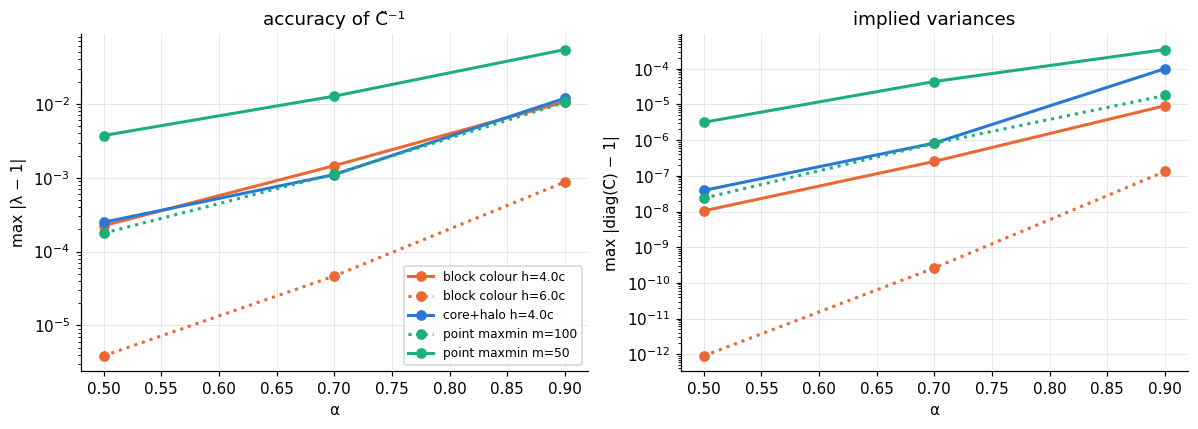

In [8]:
sel = {"core+halo h=4.0c": "core+halo", "block colour h=4.0c": "block", "block colour h=6.0c": "block", "point maxmin m=50": "point", "point maxmin m=100": "point"}
s = acc[(acc.channel == 6) & (acc.slot == 28) & (acc.P == 96) & acc.label.isin(sel)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lab, grp in s.groupby("label"):
    grp = grp.sort_values("alpha")
    ls = ":" if ("6.0" in lab or "100" in lab) else "-"
    ax[0].semilogy(grp.alpha, grp.max_dev, marker="o", ls=ls, color=COL[sel[lab]], lw=2, label=lab)
    ax[1].semilogy(grp.alpha, grp.var_err_max, marker="o", ls=ls, color=COL[sel[lab]], lw=2, label=lab)
ax[0].set(xlabel="α", ylabel="max |λ − 1|", title="accuracy of C̃⁻¹"); ax[1].set(xlabel="α", ylabel="max |diag(C̃) − 1|", title="implied variances")
ax[0].legend(fontsize=8); fig.tight_layout()

### 2.3 Dependence on the number of patches

As P grows, the patches shrink, but the patch layout still comes from all data of the cycle. For ch6 at α 0.7 we compare 96, 384 and 1024 patches. Two quantities matter:
* the accuracy, which should depend on h and not on P;
* the costs per patch.

In [9]:
s = acc[(acc.channel == 6) & (acc.slot == 28) & (acc.alpha == 0.7) & acc.label.isin(["core+halo h=4.0c", "block colour h=4.0c", "block colour h=6.0c", "block id h=4.0c", "point maxmin m=50", "point patch m=50"])]
display(s.pivot_table(index="label", columns="P", values=["max_dev", "halo_over_core", "flops_apply_max", "peers_max", "sample_rounds"]).style.format("{:.2g}"))

In [10]:
others = cases[~((cases.channel == 6) & (cases.slot == 28) & cases.alpha.isin([0.5, 0.7]) & (cases.P == 96))]
for _, c in others.iterrows():
    show(c.channel, c.slot, c.alpha, c.P)

ch5.0 slot 28.0, alpha 0.5, P = 96.0, n = 11415


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,1.4e-02,0.9863,1.1e-02,1.7e-04,2.3e-03,1.2e-04,7.8e-03,0.87,9,4.5e+05,3.5e+05,1.9e+07,1.3e+07,1.6e+05,2.1e+06,-,-
core+halo h=3.0c,2.7e-03,0.9973,1.1e-04,-8.5e-06,2.4e-04,4.4e-06,1.7e-03,1.47,10,7.4e+05,3.8e+05,3.4e+07,2.7e+07,2.7e+05,2.6e+06,-,-
core+halo h=4.0c,3.2e-04,0.9997,1.2e-06,-4.2e-07,2.5e-05,7.3e-08,2.0e-04,2.14,10,1.1e+06,4.3e+05,5.5e+07,5.1e+07,3.9e+05,3.1e+06,-,-
block colour h=2.0c,2.3e-02,0.9772,1.8e-02,8.1e-05,2.9e-03,1.2e-04,1.4e-02,0.43,8,1.5e+05,-,4.2e+06,2.2e+07,7.9e+04,6.9e+05,1,4
block colour h=3.0c,3.8e-03,0.9962,1.8e-04,-4.6e-06,2.8e-04,1.1e-06,2.4e-03,0.72,9,2.0e+05,-,5.6e+06,4.0e+07,1.3e+05,9.0e+05,1,5
block colour h=4.0c,6.3e-04,0.9994,1.9e-06,-6.0e-07,3.0e-05,2.3e-08,3.9e-04,1.06,10,2.2e+05,-,7.0e+06,6.8e+07,1.9e+05,1.1e+06,1,5
block colour h=6.0c,1.5e-05,1.0000,2.9e-10,1.1e-09,2.8e-07,1.6e-12,8.4e-06,1.80,13,2.6e+05,-,1.0e+07,1.9e+08,3.3e+05,1.6e+06,1,7
block id h=4.0c,6.3e-04,0.9994,2.0e-06,-4.4e-07,2.9e-05,2.3e-08,3.9e-04,1.07,6,1.6e+05,-,7.2e+06,3.7e+07,1.9e+05,1.1e+06,1,34
point maxmin m=30,1.9e-02,0.9819,3.5e-02,2.4e-05,3.5e-03,8.3e-05,8.3e-03,2.10,52,3.5e+04,-,1.4e+06,3.0e+06,3.8e+05,7.0e+07,6,337


ch5.0 slot 28.0, alpha 0.7, P = 96.0, n = 11415


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,4.0e-02,0.9604,8.3e-02,6.9e-05,5.8e-03,1.1e-03,2.3e-02,0.87,9,4.5e+05,3.5e+05,1.9e+07,1.3e+07,1.6e+05,2.1e+06,-,-
core+halo h=3.0c,1.2e-02,0.9878,2.0e-03,-6.9e-06,1.0e-03,8.8e-05,7.2e-03,1.47,10,7.4e+05,3.8e+05,3.4e+07,2.7e+07,2.7e+05,2.6e+06,-,-
core+halo h=4.0c,1.4e-03,0.9986,4.2e-05,-4.2e-06,1.5e-04,1.5e-06,8.4e-04,2.14,10,1.1e+06,4.3e+05,5.5e+07,5.1e+07,3.9e+05,3.1e+06,-,-
block colour h=2.0c,5.6e-02,0.9438,1.3e-01,4.7e-05,7.2e-03,5.4e-04,3.5e-02,0.43,8,1.5e+05,-,4.2e+06,2.2e+07,7.9e+04,6.9e+05,1,4
block colour h=3.0c,1.3e-02,0.9868,2.6e-03,-1.1e-05,1.0e-03,1.1e-05,7.2e-03,0.72,9,2.0e+05,-,5.6e+06,4.0e+07,1.3e+05,9.0e+05,1,5
block colour h=4.0c,2.2e-03,0.9978,5.8e-05,-5.9e-06,1.7e-04,3.3e-07,1.6e-03,1.06,10,2.2e+05,-,7.0e+06,6.8e+07,1.9e+05,1.1e+06,1,5
block colour h=6.0c,8.0e-05,0.9999,2.8e-08,7.2e-08,2.9e-06,1.9e-10,5.0e-05,1.80,13,2.6e+05,-,1.0e+07,1.9e+08,3.3e+05,1.6e+06,1,7
block id h=4.0c,2.2e-03,0.9978,6.1e-05,-3.4e-06,1.6e-04,2.9e-07,1.6e-03,1.07,6,1.6e+05,-,7.2e+06,3.7e+07,1.9e+05,1.1e+06,1,34
point maxmin m=30,4.9e-02,0.9531,2.7e-01,-1.2e-04,1.0e-02,5.6e-04,2.0e-02,2.10,52,3.5e+04,-,1.4e+06,3.0e+06,3.8e+05,7.0e+07,6,337


ch5.0 slot 28.0, alpha 0.7, P = 1024.0, n = 11415


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,6.5e-02,0.9364,4.1e-01,4.3e-04,1.2e-02,3.0e-03,4.0e-02,3.73,15,3.3e+04,1.3e+04,1.2e+07,2.5e+05,6.8e+05,4.3e+06,-,-
core+halo h=3.0c,1.2e-02,0.9881,1.0e-02,8.7e-05,1.9e-03,9.0e-05,8.5e-03,7.04,25,8.5e+04,1.7e+04,3.5e+07,1.0e+06,1.3e+06,7.0e+06,-,-
core+halo h=4.0c,2.4e-03,0.9976,2.4e-04,-1.1e-05,2.9e-04,5.1e-06,1.9e-03,11.20,33,1.9e+05,2.2e+04,8.2e+07,3.5e+06,2.0e+06,1.0e+07,-,-
block colour h=2.0c,7.1e-02,0.9289,4.5e-01,5.3e-04,1.3e-02,1.1e-03,3.2e-02,1.88,15,5.8e+03,-,1.2e+06,3.4e+05,3.4e+05,1.5e+06,1,6
block colour h=3.0c,1.3e-02,0.9866,8.4e-03,1.5e-05,1.8e-03,3.3e-05,8.1e-03,3.52,25,9.2e+03,-,1.9e+06,1.3e+06,6.4e+05,2.5e+06,1,10
block colour h=4.0c,2.5e-03,0.9975,1.7e-04,-2.2e-06,2.6e-04,1.2e-06,1.4e-03,5.58,29,1.4e+04,-,2.8e+06,3.6e+06,1.0e+06,3.7e+06,1,15
block colour h=6.0c,1.2e-04,0.9999,1.2e-07,2.9e-08,5.6e-06,1.7e-09,6.7e-05,10.80,55,2.5e+04,-,4.9e+06,2.3e+07,2.0e+06,6.6e+06,1,24
block id h=4.0c,2.9e-03,0.9971,2.7e-04,-2.6e-06,3.1e-04,9.7e-07,1.6e-03,5.59,21,9.0e+03,-,3.0e+06,1.4e+06,1.0e+06,3.8e+06,1,246
point maxmin m=30,4.9e-02,0.9531,2.7e-01,-1.2e-04,1.0e-02,5.6e-04,2.0e-02,8.89,93,6.0e+03,-,1.4e+06,5.2e+05,1.6e+06,1.7e+08,6,478


... (10 outputs left out)

ch9.0 slot 28.0, alpha 0.5, P = 96.0, n = 924


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,9.5e-03,0.9907,5.7e-04,3.6e-06,1.9e-03,5.8e-05,5.8e-03,0.87,5,1.0e+05,-,4.1e+05,1.3e+06,1.3e+04,2.3e+05,-,-
core+halo h=3.0c,1.8e-03,0.9982,6.0e-06,-8.7e-07,1.7e-04,1.7e-06,8.3e-04,1.47,6,1.5e+05,-,6.8e+05,2.4e+06,2.2e+04,2.8e+05,-,-
core+halo h=4.0c,1.2e-04,0.9999,4.5e-08,2.8e-08,1.1e-05,8.5e-09,6.9e-05,2.14,6,1.9e+05,-,1.1e+06,3.4e+06,3.2e+04,3.4e+05,-,-
block colour h=2.0c,1.3e-02,0.9874,5.8e-04,2.3e-05,2.0e-03,2.4e-05,7.1e-03,0.42,5,3.1e+04,-,8.7e+04,2.7e+06,6.3e+03,6.3e+04,1,3
block colour h=3.0c,1.1e-03,0.9989,3.4e-06,2.1e-06,1.6e-04,1.3e-07,7.0e-04,0.69,6,4.0e+04,-,1.1e+05,4.5e+06,1.0e+04,7.8e+04,1,3
block colour h=4.0c,1.9e-04,0.9998,7.6e-08,1.3e-07,1.4e-05,5.5e-09,9.6e-05,1.06,6,3.4e+04,-,1.3e+05,3.3e+06,1.6e+04,9.2e+04,1,4
block colour h=6.0c,1.3e-06,1.0000,1.3e-12,-9.5e-11,5.3e-08,2.3e-13,6.6e-07,1.64,8,4.7e+04,-,1.7e+05,7.8e+06,2.4e+04,1.2e+05,1,4
block id h=4.0c,1.9e-04,0.9998,6.4e-08,-2.5e-07,1.3e-05,7.4e-10,8.6e-05,1.04,5,2.3e+04,-,1.3e+05,1.4e+06,1.5e+04,1.1e+05,1,9
point maxmin m=30,1.3e-02,0.9872,9.0e-04,1.7e-05,1.4e-03,2.0e-05,7.0e-03,5.57,45,7.5e+03,-,1.1e+05,6.6e+05,8.2e+04,5.1e+06,6,162


ch9.0 slot 28.0, alpha 0.5, P = 1024.0, n = 924


,max_dev,lam_min,kl,jo_rel,z_rel,var_err_max,cov_err_max,halo_over_core,peers_max,flops_apply_max,flops_apply_explicit_max,flops_apply_total,flops_setup_max,bytes_apply,bytes_setup,rounds_setup,sample_rounds
label,,,,,,,,,,,,,,,,,
core+halo h=2.0c,2.1e-02,0.9786,3.3e-03,1.7e-04,3.6e-03,3.0e-04,1.3e-02,4.05,15,1.5e+04,-,5.0e+05,7.9e+04,6.0e+04,4.9e+05,-,-
core+halo h=3.0c,3.3e-03,0.9967,2.9e-05,-3.6e-06,3.3e-04,7.1e-06,1.9e-03,7.38,24,4.5e+04,-,1.4e+06,4.0e+05,1.1e+05,8.2e+05,-,-
core+halo h=4.0c,2.4e-04,0.9998,2.3e-07,-9.5e-07,2.5e-05,3.6e-08,1.3e-04,11.19,30,9.0e+04,-,2.9e+06,1.1e+06,1.7e+05,1.2e+06,-,-
block colour h=2.0c,1.4e-02,0.9861,2.2e-03,-7.1e-05,2.8e-03,2.0e-04,8.4e-03,1.84,14,1.2e+03,-,4.1e+04,6.3e+04,2.7e+04,1.2e+05,1,6
block colour h=3.0c,2.0e-03,0.9980,1.7e-05,4.4e-06,2.3e-04,7.0e-07,1.4e-03,3.49,21,2.2e+03,-,6.2e+04,3.5e+05,5.2e+04,2.1e+05,1,10
block colour h=4.0c,1.5e-04,0.9999,9.6e-08,-7.3e-07,1.9e-05,7.1e-09,9.0e-05,5.20,27,3.3e+03,-,8.5e+04,9.9e+05,7.7e+04,2.9e+05,1,16
block colour h=6.0c,5.5e-06,1.0000,2.3e-11,-4.9e-09,2.3e-07,7.2e-13,3.4e-06,9.22,38,4.3e+03,-,1.2e+05,2.2e+06,1.4e+05,4.8e+05,1,23
block id h=4.0c,2.1e-04,0.9998,2.3e-07,-9.6e-07,2.5e-05,5.4e-09,1.1e-04,5.52,18,2.0e+03,-,8.9e+04,2.6e+05,8.2e+04,3.2e+05,1,50
point maxmin m=30,1.3e-02,0.9872,9.0e-04,1.7e-05,1.4e-03,2.0e-05,7.0e-03,16.90,69,9.9e+02,-,1.1e+05,8.7e+04,2.5e+05,1.0e+07,6,201


## 3. All 36 groups of the cycle, 96 to 1024 tasks

These are structural counts from `vecchia_scaling.py`, without factorisation. Every patch holds all groups. Per task, summed over the groups:
* the halo,
* flops of one application,
* flops of the setup,
* bytes of one application (halo + adjoint halo),
* peers.

Sampling rounds and point-setup rounds are also counted. The block variant uses the colour sequence.

In [11]:
sc = json.load(open(RES / "scaling.json"))
recs = []
for x in sc["results"]:
    for k in ("core_halo", "core_halo_explicit", "block_h3", "block_h4", "block_h4_id", "point_m50", "point_m100"):
        if k not in x:
            continue
        y = x[k]
        recs.append(dict(P=x["P"], op=k, diam_km=x["patch_diam_km"], colours=x["colours"], halo_over_core=y["halo_over_core"],
                         apply_max=y["flops_apply"]["max"], apply_mean=y["flops_apply"]["mean"],
                         setup_max=y["flops_setup"]["max"], setup_mean=y["flops_setup"]["mean"],
                         words_max=y["words"]["max"], bytes_max=y["bytes_apply"]["max"],
                         peers_max=y["peers"]["max"], peers_mean=y["peers"]["mean"],
                         sample_rounds=y.get("sample_rounds", np.nan), setup_rounds=y.get("setup_rounds", np.nan)))
S = pd.DataFrame(recs)
print(f"n = {sc['n']}, groups = {sc['n_groups']}")
display(S.pivot_table(index="op", columns="P", values=["halo_over_core", "apply_max", "setup_max", "bytes_max", "peers_max", "sample_rounds"]).style.format("{:.3g}"))

n = 203633, groups = 36


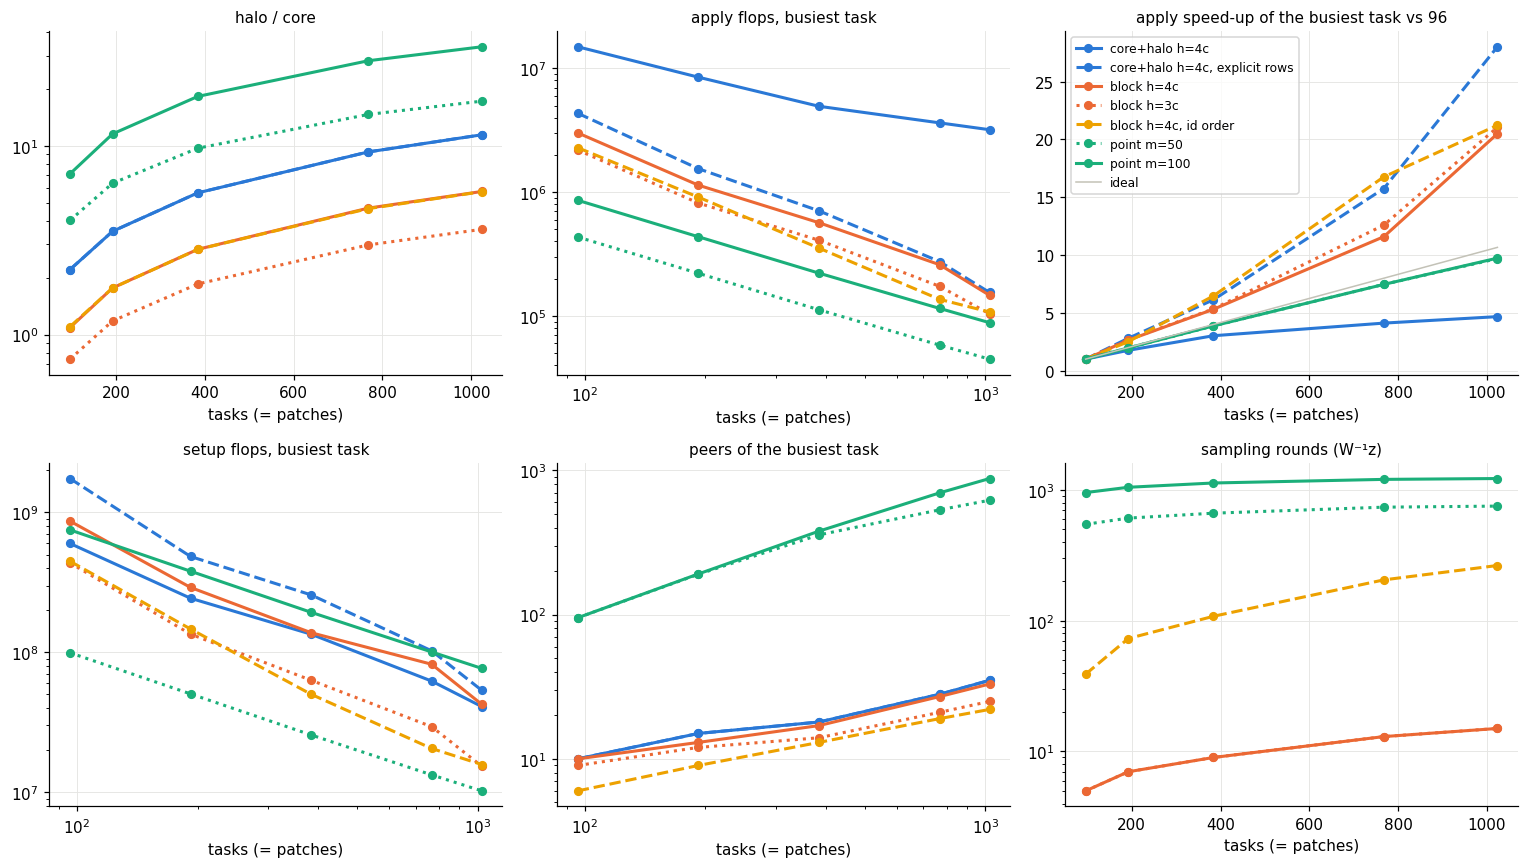

In [12]:
OPC = {"core_halo": ("core+halo h=4c", COL["core+halo"], "-"),
       "core_halo_explicit": ("core+halo h=4c, explicit rows", COL["core+halo"], "--"), "block_h4": ("block h=4c", COL["block"], "-"), "block_h3": ("block h=3c", COL["block"], ":"),
       "block_h4_id": ("block h=4c, id order", "#eda100", "--"),
       "point_m50": ("point m=50", COL["point"], ":"), "point_m100": ("point m=100", COL["point"], "-")}
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for op, (lab, col, ls) in OPC.items():
    s = S[S.op == op].sort_values("P")
    if s.empty:
        continue
    kw = dict(color=col, ls=ls, lw=2, marker="o", ms=5, label=lab)
    axs[0, 0].plot(s.P, s.halo_over_core, **kw)
    axs[0, 1].loglog(s.P, s.apply_max, **kw)
    axs[0, 2].plot(s.P, s.apply_max.iloc[0] / s.apply_max, **kw)
    axs[1, 0].loglog(s.P, s.setup_max, **kw)
    axs[1, 1].loglog(s.P, s.peers_max, **kw)
    if not op.startswith("core_halo"):
        axs[1, 2].semilogy(s.P, s.sample_rounds, **kw)
axs[0, 2].plot([96, 1024], [1, 1024 / 96], color="#c3c2b7", lw=1, label="ideal")
for ax, t in zip(axs.flat, ("halo / core", "apply flops, busiest task", "apply speed-up of the busiest task vs 96",
                            "setup flops, busiest task", "peers of the busiest task", "sampling rounds (W⁻¹z)")):
    ax.set_title(t, fontsize=10); ax.set_xlabel("tasks (= patches)")
axs[0, 0].set_yscale("log"); axs[0, 2].legend(fontsize=8)
fig.tight_layout()

In [13]:
pm = pd.DataFrame([dict(P=x["P"], m=m, **x[f"point_m{m}"]["reach_km"], setup_rounds=x[f"point_m{m}"]["setup_rounds"],
                        **{f"certified_after_{k}": v for k, v in x[f"point_m{m}"]["setup_rounds_frac"].items()})
                   for x in sc["results"] for m in (50, 100)])
print("point Vecchia: reach of the conditioning sets (km; c = 115 km, today's halo 460 km), and the fraction of data whose")
print("neighbour search is certified after k rounds of radius doubling from R0 = 4c = 460 km")
display(pm[pm.P == 96].drop(columns="P").set_index("m").style.format("{:.3g}"))

point Vecchia: reach of the conditioning sets (km; c = 115 km, today's halo 460 km), and the fraction of data whose
neighbour search is certified after k rounds of radius doubling from R0 = 4c = 460 km


,median,p90,max,setup_rounds,certified_after_1,certified_after_2,certified_after_3,certified_after_4,certified_after_5,certified_after_6
m,,,,,,,,,,
50,607,1.81e+03,1.16e+04,6,0.299,0.715,0.903,0.968,0.988,1
100,896,2.69e+03,1.16e+04,6,0.00757,0.517,0.819,0.938,0.978,1


## 4. Summary

See `VECCHIA_REPORT.md` at the top of the repository for the conclusions and recommendations. The numbers quoted there are the ones in this notebook.